# **RERUN SHAP IN BEST MODELS**

# **Give google drive access**

In [1]:
from google.colab import drive
# Unmount the drive if already mounted
drive.flush_and_unmount()

Drive not mounted, so nothing to flush and unmount.


In [2]:
from google.colab import drive
drive.mount("/content/drive", force_remount=True)
%cd "/content/drive/My Drive/Colab Notebooks/Ozonation model"

Mounted at /content/drive
/content/drive/My Drive/Colab Notebooks/Ozonation model


# **Upload best model dataset and scaler**

In [3]:
import os
import joblib
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

#model=joblib.load("COL BACTERIA RESULTS/New Volumes/AdaB Coliform 12 features New Volumes 20/ada_kcol_12_newvol_20.pkl")
#scaler_X=joblib.load("COL BACTERIA RESULTS/New Volumes/AdaB Coliform 12 features New Volumes 20/feature_scaler.pkl")
#scaler_y=joblib.load("COL BACTERIA RESULTS/New Volumes/AdaB Coliform 12 features New Volumes 20/target_scaler.pkl")
input_path = 'X_bromate.xlsx'
X = pd.read_excel(input_path)
input_path = 'y_bromate.xlsx'
y = pd.read_excel(input_path)

In [3]:
import os
import joblib
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

model=joblib.load("COL BACTERIA RESULTS/New Volumes/AdaB Coliform 12 features New Volumes 20/ada_kcol_12_newvol_20.pkl")
scaler_X=joblib.load("COL BACTERIA RESULTS/New Volumes/AdaB Coliform 12 features New Volumes 20/feature_scaler.pkl")
scaler_y=joblib.load("COL BACTERIA RESULTS/New Volumes/AdaB Coliform 12 features New Volumes 20/target_scaler.pkl")
input_path = 'Coliform Bacteria best model/NEW VOLUMES/X_logremoval.xlsx'
X = pd.read_excel(input_path)
input_path = 'Coliform Bacteria best model/NEW VOLUMES/y_logremoval.xlsx'
y = pd.read_excel(input_path)

In [7]:
import os
import joblib
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

model=joblib.load("OZONE RESULTS/_Results with new volumes/XGB 8 features features New Volumes 20/xgb_7features_newvol.pkl")
scaler_X=joblib.load("OZONE RESULTS/_Results with new volumes/XGB 8 features features New Volumes 20//feature_scaler.pkl")
scaler_y=joblib.load("OZONE RESULTS/_Results with new volumes/XGB 8 features features New Volumes 20//target_scaler.pkl")
input_path = 'X_CT.xlsx'
X = pd.read_excel(input_path)
input_path = 'y_CT.xlsx'
y = pd.read_excel(input_path)

In [17]:
testsize = float(input("Set the testing size(e.g. 0.1 = 10% for testing):"))
rdmstate = int(input("Set the random state:"))
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(X,y,range(len(X)), test_size=testsize, random_state=rdmstate) # this is for the decision trees approach
y_all = y['K_Hom_estimation']

Set the testing size(e.g. 0.1 = 10% for testing):0.2
Set the random state:42


# **Rerun SHAP values**

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(



1. METRICS  --  logremoval  (log10 removal)
  n test rows       : 63
  R2                : 0.8895
  RMSE              : 0.0026 log10 removal
  MAE               : 0.0017 log10 removal
  RMSE / MAE        : 1.540    (~1.25 Gaussian; higher = heavy tails)
  y_test mean / std : 0.0181 / 0.0079
  sd(predictions)   : 0.0069
  R2 implied by std : 0.8913   (must match R2)

2. SANITY CHECKS for target = logremoval
  n samples            : 315
  target range         : 0.001 to 0.044 log10 removal
  target std           : 0.0078
  distinct values      : 312  (99.0% of rows)
  most common value    : 0.017  in 2 rows (0.6%)
  rows at the maximum  : 0.3%
  rows at the minimum  : 0.3%

3. SHAP
  TreeExplainer unavailable (InvalidModelError) -- falling back.
  method               : PermutationExplainer (n_bg=20, max_evals=200)
  base value E[f]      : 0.0175 log10 removal
  sd(sum of SHAP)      : 0.0069 log10 removal
  sd(predictions)      : 0.0069 log10 removal   (should match)
  max additivity er

/tmp/ipykernel_2492/728726661.py:225: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, Xte_raw, feature_names=FEATURES, show=False)


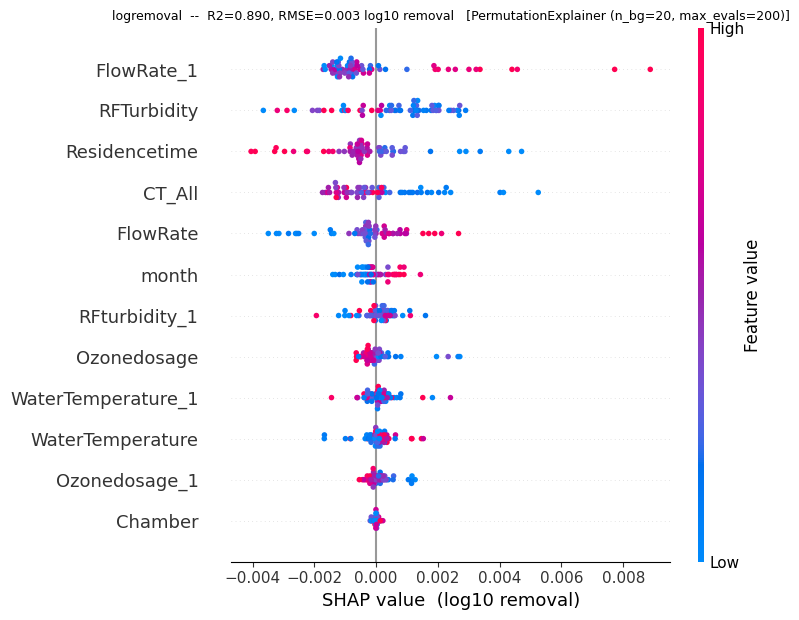

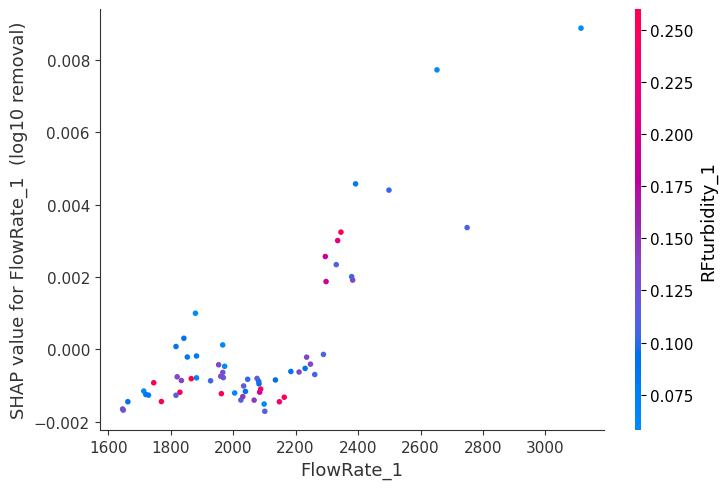


Saved: shap_logremoval_beeswarm.png, shap_logremoval_dependence_FlowRate_1.png


In [18]:
"""
============================================================================
shap_rerun_v2.py  --  one script for all three models
                      (CT / bromate / log coliform removal)
============================================================================
Set TASK at the top, point the CONFIG block at your objects, run.

Handles:
  * any model  -- uses TreeExplainer when it is valid (XGBoost, GBR, RF),
                  falls back to a fast PermutationExplainer for AdaBoost
  * any scaling -- scaler_X / scaler_y may be None if you did not scale
  * output always converted to PHYSICAL units of the target
  * task-specific sanity checks:
        CT          -> is the target just an algebraic function of inputs?
        logremoval  -> is the target censored at a detection limit?
  * baseline-centering check (catches the "all points on one side of zero"
    pattern seen in the CT plot)
============================================================================
"""

import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

# ===========================================================================
# CONFIG
# ===========================================================================
TASK = "logremoval"                 # "CT" | "bromate" | "logremoval"

UNITS = {"CT": "mg*min/L",
         "bromate": "ug/L",
         "logremoval": "log10 removal"}[TASK]

# --- your objects -------------------------------------------------------
# model     : the fitted regressor for THIS task
# scaler_X  : fitted on X_train  (or None if you did not scale X)
# scaler_y  : fitted on y_train  (or None if you did not scale y)
# X_train   : RAW training features (DataFrame)
# X_test    : RAW test features     (DataFrame)
# y_test    : RAW test target       (Series / 1-D array, physical units)
# y_all     : RAW target, full dataset -- used for the censoring check
# ------------------------------------------------------------------------

N_BACKGROUND = 20           # only used if TreeExplainer is unavailable
MAX_EVALS = 200             # ditto
RANDOM_STATE = 0

FEATURES = list(X_test.columns)
Xtr_raw = pd.DataFrame(X_train, columns=FEATURES).astype(float)
Xte_raw = pd.DataFrame(X_test, columns=FEATURES).astype(float)
y_true = np.asarray(y_test, dtype=float).ravel()

Xtr_in = scaler_X.transform(Xtr_raw.values) if scaler_X is not None else Xtr_raw.values
Xte_in = scaler_X.transform(Xte_raw.values) if scaler_X is not None else Xte_raw.values

# linear map from model output back to physical units:  y = S * y_model + M
if scaler_y is not None:
    M = float(scaler_y.inverse_transform([[0.0]])[0, 0])
    S = float(scaler_y.inverse_transform([[1.0]])[0, 0]) - M
else:
    M, S = 0.0, 1.0


def predict_phys(Xin):
    Xin = np.atleast_2d(np.asarray(Xin, dtype=float))
    return np.asarray(model.predict(Xin), dtype=float).ravel() * S + M


hdr = lambda t: print("\n" + "=" * 74 + f"\n{t}\n" + "=" * 74)

# ===========================================================================
# 1. METRICS -- all from the same arrays, in physical units
# ===========================================================================
y_pred = predict_phys(Xte_in)
r2 = r2_score(y_true, y_pred)
rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
mae = mean_absolute_error(y_true, y_pred)

hdr(f"1. METRICS  --  {TASK}  ({UNITS})")
print(f"  n test rows       : {len(y_true)}")
print(f"  R2                : {r2:.4f}")
print(f"  RMSE              : {rmse:.4f} {UNITS}")
print(f"  MAE               : {mae:.4f} {UNITS}")
print(f"  RMSE / MAE        : {rmse / mae:.3f}    (~1.25 Gaussian; higher = heavy tails)")
print(f"  y_test mean / std : {y_true.mean():.4f} / {y_true.std(ddof=1):.4f}")
print(f"  sd(predictions)   : {y_pred.std(ddof=1):.4f}")
print(f"  R2 implied by std : {1 - rmse ** 2 / y_true.var(ddof=1):.4f}   (must match R2)")

# ===========================================================================
# 2. TASK-SPECIFIC SANITY CHECKS
# ===========================================================================
hdr(f"2. SANITY CHECKS for target = {TASK}")

if TASK == "CT":
    # CT = concentration x contact time. If ozone dose and residence time are
    # inputs, the "model" may just be reproducing that definition.
    cand = {c.lower(): c for c in FEATURES}
    dose = cand.get("ozonedosage")
    rt = next((cand[k] for k in cand if k.startswith("residence")), None)
    print("  Is the target an algebraic function of its own inputs?")
    if dose and rt:
        prod = (Xte_raw[dose] * Xte_raw[rt]).values.reshape(-1, 1)
        lin = LinearRegression().fit(prod, y_true)
        r2_id = r2_score(y_true, lin.predict(prod))
        print(f"    OLS of target on ({dose} x {rt}) : R2 = {r2_id:.4f}")
        if r2_id > 0.90:
            print("    *** CT is essentially dose x time. This is a definition,")
            print("        not an empirical model. Either predict the ozone")
            print("        RESIDUAL / decay constant instead, or drop dose and")
            print("        residence time from the feature set.")
    else:
        print(f"    ozone dose and/or residence time not found in {FEATURES}")
    flow = cand.get("flowrate")
    if flow and rt:
        print(f"    corr({flow}, {rt}) = {Xte_raw[flow].corr(Xte_raw[rt]):+.3f}"
              "   (flow and residence time are usually near-redundant)")

elif TASK == "logremoval":
    ya = np.asarray(y_all, dtype=float).ravel()
    v, c = np.unique(np.round(ya, 6), return_counts=True)
    top_val, top_cnt = v[c.argmax()], c.max()
    print(f"  n samples            : {len(ya)}")
    print(f"  target range         : {ya.min():.3f} to {ya.max():.3f} {UNITS}")
    print(f"  target std           : {ya.std(ddof=1):.4f}")
    print(f"  distinct values      : {len(v)}  ({100 * len(v) / len(ya):.1f}% of rows)")
    print(f"  most common value    : {top_val:.3f}  in {top_cnt} rows "
          f"({100 * top_cnt / len(ya):.1f}%)")
    print(f"  rows at the maximum  : {100 * (ya >= ya.max() - 1e-9).mean():.1f}%")
    print(f"  rows at the minimum  : {100 * (ya <= ya.min() + 1e-9).mean():.1f}%")
    if top_cnt / len(ya) > 0.15:
        print("    *** A large share of rows share one value -- consistent with")
        print("        effluent counts pinned at the detection limit. Log removal")
        print("        is then bounded by INFLUENT load, not by treatment, which")
        print("        is how turbidity ends up 'improving' disinfection and CT")
        print("        ends up inverted. Consider a censored/Tobit model, or")
        print("        model effluent concentration with a non-detect indicator.")

# ===========================================================================
# 3. SHAP -- TreeExplainer if valid, else fast Permutation. Physical units.
# ===========================================================================
hdr("3. SHAP")

sv = base = None
method = None
try:
    te = shap.TreeExplainer(model)
    sv_n = np.asarray(te.shap_values(Xte_in), dtype=float)
    base_n = float(np.ravel(te.expected_value)[0])
    pn = np.asarray(model.predict(Xte_in), dtype=float).ravel()
    err = np.abs(base_n + sv_n.sum(1) - pn).max()
    if err < 1e-4 * max(1.0, np.abs(pn).max()):
        sv, base, method = sv_n * S, base_n * S + M, "TreeExplainer (exact)"
        print(f"  TreeExplainer valid. additivity error = {err:.2e} (model units)")
    else:
        print(f"  TreeExplainer additivity FAILED ({err:.2e}) -- falling back.")
except Exception as e:
    print(f"  TreeExplainer unavailable ({type(e).__name__}) -- falling back.")

if sv is None:
    bg = shap.utils.sample(Xtr_in, min(N_BACKGROUND, len(Xtr_in)), random_state=RANDOM_STATE)
    ex = shap.PermutationExplainer(
        predict_phys, shap.maskers.Independent(bg, max_samples=len(bg)), seed=RANDOM_STATE)
    expl = ex(Xte_in, max_evals=max(MAX_EVALS, 2 * len(FEATURES) + 1), silent=True)
    sv = np.asarray(expl.values, dtype=float)
    base = float(np.ravel(expl.base_values)[0])
    method = f"PermutationExplainer (n_bg={len(bg)}, max_evals={MAX_EVALS})"

add_err = np.abs(base + sv.sum(1) - y_pred).max()
print(f"  method               : {method}")
print(f"  base value E[f]      : {base:.4f} {UNITS}")
print(f"  sd(sum of SHAP)      : {sv.sum(1).std(ddof=1):.4f} {UNITS}")
print(f"  sd(predictions)      : {y_pred.std(ddof=1):.4f} {UNITS}   (should match)")
print(f"  max additivity error : {add_err:.3e} {UNITS}")

# ---- baseline-centering check -------------------------------------------
mean_sv, sd_sv = sv.mean(0), sv.std(0, ddof=1)
off = np.abs(mean_sv) / (sd_sv + 1e-12)
bad = [(FEATURES[j], mean_sv[j], sd_sv[j], off[j]) for j in np.argsort(-off) if off[j] > 1.5]
print("\n  Baseline centering (mean SHAP should sit near 0 for most features):")
if bad:
    for f, m, s, o in bad[:6]:
        print(f"    {f:<22} mean={m:+.4f}  sd={s:.4f}  |mean|/sd={o:.1f}")
    print("    *** Features displaced entirely to one side of zero mean the")
    print("        explained rows and the explainer's background come from")
    print("        different distributions. Explain the same rows you scored,")
    print("        and draw the background from X_train.")
else:
    print("    OK -- no feature is strongly displaced from zero.")

# ===========================================================================
# 4. IMPORTANCE + COLLINEARITY
# ===========================================================================
imp = pd.DataFrame({
    "feature": FEATURES,
    f"mean_abs_SHAP_{UNITS}": np.abs(sv).mean(0),
    f"max_abs_SHAP_{UNITS}": np.abs(sv).max(0),
    "direction_corr": [
        np.corrcoef(Xte_raw.iloc[:, j], sv[:, j])[0, 1]
        if (Xte_raw.iloc[:, j].std() > 0 and sv[:, j].std() > 0) else np.nan
        for j in range(len(FEATURES))],
}).sort_values(f"mean_abs_SHAP_{UNITS}", ascending=False).reset_index(drop=True)

hdr(f"4. IMPORTANCE ({UNITS})   direction_corr > 0 = higher feature raises prediction")
print(imp.to_string(index=False, float_format=lambda v: f"{v: .4f}"))

hdr("5. COLLINEARITY (|r| > 0.85)")
C = Xtr_raw.corr().abs()
pairs = [(FEATURES[i], FEATURES[j], C.iloc[i, j])
         for i in range(len(FEATURES)) for j in range(i + 1, len(FEATURES))
         if C.iloc[i, j] > 0.85]
if pairs:
    for a, b, c in sorted(pairs, key=lambda t: -t[2]):
        print(f"  |r| = {c:.3f}   {a}  <->  {b}")
    print("\n  Shapley values are not identified under near-duplicate features:")
    print("  credit splits arbitrarily and signs can invert. Keep one per pair.")
else:
    print("  none")

# ===========================================================================
# 6. PLOTS
# ===========================================================================
shap.summary_plot(sv, Xte_raw, feature_names=FEATURES, show=False)
plt.xlabel(f"SHAP value  ({UNITS})")
plt.title(f"{TASK}  --  R2={r2:.3f}, RMSE={rmse:.3f} {UNITS}   [{method}]", fontsize=9)
plt.tight_layout()
plt.savefig(f"shap_{TASK}_beeswarm.png", dpi=200, bbox_inches="tight")
plt.show()

top = imp.loc[0, "feature"]
shap.dependence_plot(top, sv, Xte_raw, feature_names=FEATURES, show=False)
plt.ylabel(f"SHAP value for {top}  ({UNITS})")
plt.tight_layout()
plt.savefig(f"shap_{TASK}_dependence_{top}.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"\nSaved: shap_{TASK}_beeswarm.png, shap_{TASK}_dependence_{top}.png")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


1. METRICS  (all computed on the same test arrays, in ug/L)
  n test rows        : 207
  R2                 : 0.9605
  RMSE               : 0.1553 ug/L
  MAE                : 0.0661 ug/L
  RMSE / MAE         : 2.348   (~1.25 = Gaussian; higher = heavy tails)
  y_test mean / std  : 1.6174 / 0.7834 ug/L
  sd(predictions)    : 0.7596 ug/L
  R2 implied by std  : 0.9607   (must match R2 above)

2. TreeExplainer additivity test  (the suspected bug)
  TreeExplainer REFUSES this model: InvalidModelError
    Model type not yet supported by TreeExplainer: <class 'sklearn.ensemble._weight_boosting.AdaBoostRegressor'>
  -> Recent shap versions do not support AdaBoostRegressor at all.
     If your original beeswarm came from TreeExplainer, it was NOT
     produced by this model object. Check which model you explained.

3. Recomputing SHAP (model-agnostic, output in ug/L)
  base value (E[f])         : 1.6463 ug/L
  sd(sum of SHAP)           : 0.7596 ug/L
  sd(predictions)           : 0.7596 ug/L   (

/tmp/ipykernel_1689/3114282706.py:185: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, Xte_raw, feature_names=FEATURES, show=False)


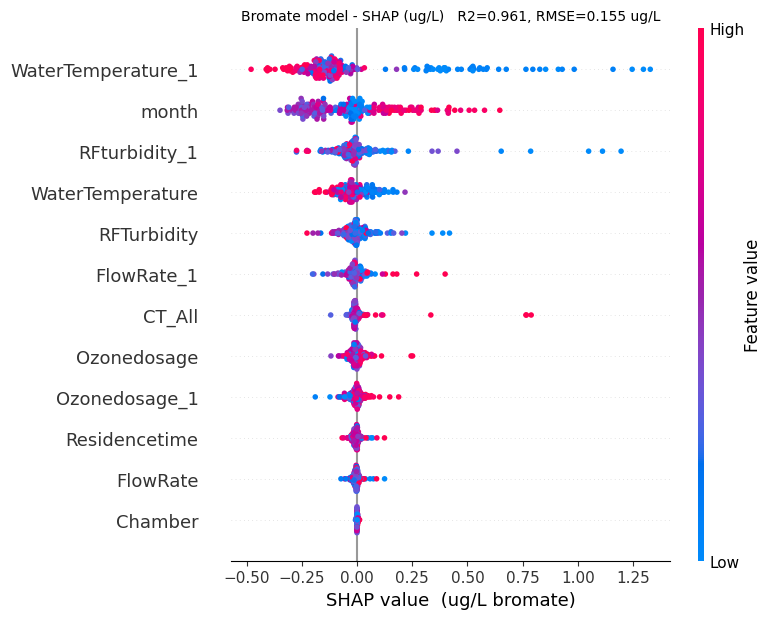

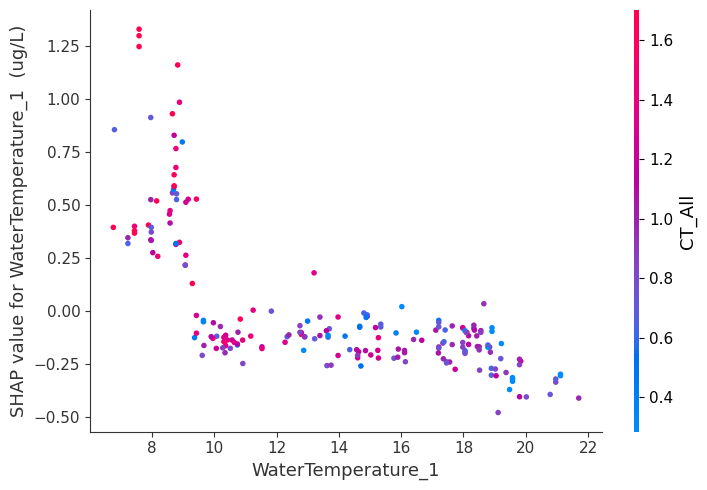


Saved: shap_beeswarm_ugL.png, shap_dependence_WaterTemperature_1.png


In [6]:
"""
============================================================================
SHAP diagnostic + corrected re-run  -- bromate / AdaBoost model
============================================================================
Paste into your notebook AFTER your model is fitted.

What it does:
  1. Recomputes R2 / RMSE / MAE so every number comes from one array.
  2. Tests whether TreeExplainer actually reproduces your AdaBoost
     (sklearn's AdaBoostRegressor aggregates by WEIGHTED MEDIAN, which
     breaks TreeSHAP's additivity assumption -- this is the suspected bug).
  3. Recomputes SHAP with a model-agnostic explainer wrapped around a
     function that already inverse-transforms to ug/L, so the SHAP values
     come out in ug/L directly. No manual rescaling, no scaler sign traps.
  4. Verifies additivity on the new values, then plots the beeswarm in ug/L
     with RAW feature values on the colour axis.
  5. Flags collinear lag pairs (the likely cause of the sign flips).
============================================================================
"""

import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# ---------------------------------------------------------------------------
# CONFIG -- point these at your own objects, then run the file top to bottom
# ---------------------------------------------------------------------------
# model     : fitted regressor, trained on SCALED X and SCALED y
# scaler_X  : fitted on X_train only
# scaler_y  : fitted on y_train only
# X_train   : RAW training features   (DataFrame)
# X_test    : RAW test features       (DataFrame)
# y_test    : RAW test target, ug/L   (Series / 1-D array)
#
# If you scaled X and y with ONE scaler over the whole frame, split them
# first -- you need a scaler whose inverse_transform takes a single column.
# ---------------------------------------------------------------------------

FEATURES = list(X_test.columns)
N_BACKGROUND = 100        # background rows for the explainer
MAX_EVALS = 500           # permutation budget; must be >= 2*n_features + 1
RANDOM_STATE = 0

Xtr_raw = pd.DataFrame(X_train, columns=FEATURES).astype(float)
Xte_raw = pd.DataFrame(X_test,  columns=FEATURES).astype(float)
y_true = np.asarray(y_test, dtype=float).ravel()

Xtr_norm = scaler_X.transform(Xtr_raw.values)
Xte_norm = scaler_X.transform(Xte_raw.values)


def predict_ugL(Xn):
    """Model prediction, inverse-transformed to ug/L. Explained directly."""
    Xn = np.atleast_2d(np.asarray(Xn, dtype=float))
    p = np.asarray(model.predict(Xn), dtype=float).reshape(-1, 1)
    return scaler_y.inverse_transform(p).ravel()


# ===========================================================================
# 1. METRICS -- all three from the same arrays
# ===========================================================================
y_pred = predict_ugL(Xte_norm)

r2 = r2_score(y_true, y_pred)
rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
mae = mean_absolute_error(y_true, y_pred)

print("=" * 74)
print("1. METRICS  (all computed on the same test arrays, in ug/L)")
print("=" * 74)
print(f"  n test rows        : {len(y_true)}")
print(f"  R2                 : {r2:.4f}")
print(f"  RMSE               : {rmse:.4f} ug/L")
print(f"  MAE                : {mae:.4f} ug/L")
print(f"  RMSE / MAE         : {rmse / mae:.3f}   (~1.25 = Gaussian; higher = heavy tails)")
print(f"  y_test mean / std  : {y_true.mean():.4f} / {y_true.std(ddof=1):.4f} ug/L")
print(f"  sd(predictions)    : {y_pred.std(ddof=1):.4f} ug/L")
print(f"  R2 implied by std  : {1 - rmse**2 / y_true.var(ddof=1):.4f}   (must match R2 above)")

# ===========================================================================
# 2. IS TreeExplainer VALID FOR THIS MODEL?
# ===========================================================================
print()
print("=" * 74)
print("2. TreeExplainer additivity test  (the suspected bug)")
print("=" * 74)

tree_ok = False
try:
    tree_exp = shap.TreeExplainer(model)
    sv_tree = tree_exp.shap_values(Xte_norm, check_additivity=False)
    sv_tree = np.asarray(sv_tree, dtype=float)
    pred_norm = np.asarray(model.predict(Xte_norm), dtype=float)
    recon = float(tree_exp.expected_value) + sv_tree.sum(axis=1)
    err = np.abs(recon - pred_norm).max()

    print(f"  sd(model output, scaled units) : {pred_norm.std(ddof=1):.6f}")
    print(f"  sd(sum of TreeSHAP values)     : {sv_tree.sum(axis=1).std(ddof=1):.6f}")
    print(f"  max additivity error           : {err:.6f}")
    tree_ok = err < 1e-4 * max(1.0, abs(pred_norm).max())
    print(f"  -> TreeExplainer is {'VALID' if tree_ok else 'INVALID for this model'}")
    if not tree_ok:
        print("     (expected: AdaBoostRegressor returns a weighted MEDIAN of its")
        print("      trees, which TreeSHAP cannot decompose additively)")
except Exception as e:
    print(f"  TreeExplainer REFUSES this model: {type(e).__name__}")
    print(f"    {e}")
    print("  -> Recent shap versions do not support AdaBoostRegressor at all.")
    print("     If your original beeswarm came from TreeExplainer, it was NOT")
    print("     produced by this model object. Check which model you explained.")

# ===========================================================================
# 3. CORRECT SHAP -- model-agnostic, already in ug/L
# ===========================================================================
print()
print("=" * 74)
print("3. Recomputing SHAP (model-agnostic, output in ug/L)")
print("=" * 74)

rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(len(Xtr_norm), size=min(N_BACKGROUND, len(Xtr_norm)), replace=False)
background = Xtr_norm[idx]

explainer = shap.PermutationExplainer(predict_ugL, background, seed=RANDOM_STATE)
expl = explainer(Xte_norm, max_evals=max(MAX_EVALS, 2 * len(FEATURES) + 1), silent=True)

sv = np.asarray(expl.values, dtype=float)
base = float(np.ravel(expl.base_values)[0])

recon = base + sv.sum(axis=1)
add_err = np.abs(recon - y_pred).max()

print(f"  base value (E[f])         : {base:.4f} ug/L")
print(f"  sd(sum of SHAP)           : {sv.sum(axis=1).std(ddof=1):.4f} ug/L")
print(f"  sd(predictions)           : {y_pred.std(ddof=1):.4f} ug/L   (should match)")
print(f"  max additivity error      : {add_err:.6f} ug/L")
print(f"  -> {'PASS' if add_err < 0.01 * max(1e-9, y_pred.std(ddof=1)) else 'CHECK: raise MAX_EVALS'}")

# ===========================================================================
# 4. IMPORTANCE TABLE, in physical units
# ===========================================================================
imp = (pd.DataFrame({
    "feature": FEATURES,
    "mean_abs_SHAP_ugL": np.abs(sv).mean(axis=0),
    "max_abs_SHAP_ugL": np.abs(sv).max(axis=0),
    "signed_corr_with_feature": [
        np.corrcoef(Xte_raw.iloc[:, j], sv[:, j])[0, 1]
        if (Xte_raw.iloc[:, j].std() > 0 and sv[:, j].std() > 0) else np.nan
        for j in range(len(FEATURES))
    ],
}).sort_values("mean_abs_SHAP_ugL", ascending=False).reset_index(drop=True))

print()
print("=" * 74)
print("4. Feature importance in ug/L")
print("   signed_corr > 0  ->  higher feature value raises predicted bromate")
print("=" * 74)
print(imp.to_string(index=False, float_format=lambda v: f"{v: .4f}"))

# ===========================================================================
# 5. COLLINEARITY -- the likely source of the paired sign flips
# ===========================================================================
print()
print("=" * 74)
print("5. Lag-pair / collinearity check")
print("=" * 74)
corr = Xtr_raw.corr().abs()
pairs = [(FEATURES[i], FEATURES[j], corr.iloc[i, j])
         for i in range(len(FEATURES)) for j in range(i + 1, len(FEATURES))
         if corr.iloc[i, j] > 0.85]
if pairs:
    for a, b, c in sorted(pairs, key=lambda t: -t[2]):
        print(f"  |r| = {c:.3f}   {a}  <->  {b}")
    print("\n  Shapley values are not identified under near-duplicate features:")
    print("  credit is split arbitrarily and the signs can invert. Drop one of")
    print("  each pair (or replace with a residence-time-matched average) and refit.")
else:
    print("  No pair above |r| = 0.85.")

# ===========================================================================
# 6. PLOTS
# ===========================================================================
shap.summary_plot(sv, Xte_raw, feature_names=FEATURES, show=False)
plt.xlabel("SHAP value  (ug/L bromate)")
plt.title(f"Bromate model - SHAP (ug/L)   R2={r2:.3f}, RMSE={rmse:.3f} ug/L", fontsize=10)
plt.tight_layout()
plt.savefig("shap_beeswarm_ugL.png", dpi=200, bbox_inches="tight")
plt.show()

top = imp.loc[0, "feature"]
shap.dependence_plot(top, sv, Xte_raw, feature_names=FEATURES,
                     interaction_index="auto", show=False)
plt.ylabel(f"SHAP value for {top}  (ug/L)")
plt.tight_layout()
plt.savefig(f"shap_dependence_{top}.png", dpi=200, bbox_inches="tight")
plt.show()

print("\nSaved: shap_beeswarm_ugL.png, shap_dependence_%s.png" % top)